In [1]:
!pip install pyreadstat

In [2]:

import pandas as pd
import numpy as np
from  google.colab import drive


In [ ]:
uploaded = drive.mount('/content/drive')
food = '/content/drive/MyDrive/food.dta'
nonfood = '/content/drive/MyDrive/nonfood.dta'
HH_Members_Information = '/content/drive/MyDrive/HH_Members_Information.dta'
HH_Information = '/content/drive/MyDrive/HH_Information.dta'
Consumption_aggregate = '/content/drive/MyDrive/Consumption_aggregate.dta'


Mounted at /content/drive


In [ ]:
all_array = np.array([food, nonfood, HH_Information, HH_Members_Information, Consumption_aggregate])
for i in range(len(all_array)):
    try:
        pd.read_stata(all_array[i], convert_categoricals="False")
        print("Successfuly read:", all_array[i])
    except:
        print("Failed to read:", all_array[i])





Successfuly read: /content/drive/MyDrive/food.dta
Failed to read: /content/drive/MyDrive/nonfood.dta
Successfuly read: /content/drive/MyDrive/HH_Information.dta


/tmp/ipykernel_1111/855652681.py:4: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  pd.read_stata(all_array[i], convert_categoricals="False")


Successfuly read: /content/drive/MyDrive/HH_Members_Information.dta
Successfuly read: /content/drive/MyDrive/Consumption_aggregate.dta


In [ ]:
import os
for f in [nonfood, Consumption_aggregate]:
    size = os.path.getsize(f)
    print(f, f"{size / 1e6:.2f} MB")
    with open(f, 'rb') as file:
        header = file.read(20)
        print(header)

/content/drive/MyDrive/nonfood.dta 22.36 MB
b's\x02\x01\x00\x0c\x00\xea\xbc\x08\x00\x00\x00\x00\x00\x00\x00\x00\x00\xa0\x8d'
/content/drive/MyDrive/Consumption_aggregate.dta 1.75 MB
b's\x02\x01\x00\x14\x00\rU\x00\x00\x00\xff\xff\x7f\xa4\xb4\t\x03B\x00'


In [ ]:
try:
    pd.read_stata(nonfood, convert_categoricals=False)
    print("worked")
except Exception as e:
    print(type(e).__name__, "-", str(e))

worked


In [ ]:
!pip install pyreadstat

In [ ]:
import pyreadstat
try:
    df_nonfood, meta_nonfood = pyreadstat.read_dta(nonfood)
    print("pyreadstat succeeded:", df_nonfood.shape)
except Exception as e:
    print("pyreadstat also failed:", type(e).__name__, str(e))

pyreadstat succeeded: (572650, 12)


In [ ]:
print(df_nonfood.columns.tolist())
print(df_nonfood.head(10))
# check if there's a household ID that repeats — confirms long format
print(df_nonfood.iloc[:,0].value_counts().head())

['county', 'resid', 'clid', 'hhid', 'recall', 'section', 'nf01', 'nf04_amt', 'nf05', 'nf07_amt', 'nf08', 'weight']
   county  resid   clid  hhid  recall  section  nf01  nf04_amt nf05 nf07_amt  \
0       1      2  140.0   1.0     1.0      1.0  1906       350    6      NaN   
1       1      2  140.0   1.0     2.0      2.0  2001      1800   12      NaN   
2       1      2  140.0   1.0     2.0      2.0  2302       320    9      NaN   
3       1      2  140.0   1.0     2.0      2.0  2303        40    9      NaN   
4       1      2  140.0   1.0     2.0      2.0  2401        70    6      NaN   
5       1      2  140.0   1.0     2.0      2.0  2601       300    5      NaN   
6       1      2  140.0   1.0     2.0      2.0  2702       150    3      NaN   
7       1      2  140.0   1.0     2.0      2.0  2801      3000    9      NaN   
8       1      2  140.0   1.0     2.0      2.0  3001       180    5      NaN   
9       1      2  140.0   1.0     2.0      2.0  3004       400    5      NaN   

  nf

In [ ]:
print(meta_nonfood.variable_value_labels.get('nf01'))
print(meta_nonfood.column_names_to_labels.get('nf01'))

{2001: 'Actual monthly house rent - single room', 2002: 'Actual monthly house rent - double room', 2003: 'Actual monthly house rent - bed sitter', 2004: 'Actual monthly house rent - 1 bedroom', 2005: 'Actual monthly house rent - 2 bedroom', 2006: 'Actual monthly house rent - 3 bedroom', 2007: 'Actual monthly house rent -more than 3 bedroom', 2008: 'Actual monthly house rent - Other', 2101: 'Imputed rentals of owner-occupiers', 2102: 'Other imputed rentals', 2201: 'Cement', 2202: 'Plumbing items', 2203: 'Paint', 2204: 'Window panes/putty', 2205: 'Tiles', 2206: 'Labour charges (Mason, painter,plumber & electrician)', 2207: 'Other (Specify)', 2301: 'Water- Water Service Provider (WSP)', 2302: 'Water- Vendors', 2303: 'Garbage  and Refuse collection', 2304: 'Sewerage', 2305: 'Toilet/septic tank emptying', 2306: 'Other water related expenses (Specify)', 2401: 'Electricity', 2501: 'Gas/LPG', 2502: 'Biogas', 2601: 'Kerosene/Paraffin', 2701: 'Firewood', 2702: 'Charcoal', 2703: 'Other Cooking Fu

In [ ]:
def categorize_nonfood(code):

    code = int(code)
    if code == 1906:
        return 'communication'  # Mobile Phone Airtime
    elif code in (4702, 4704, 4705):
        return 'transport'  # City Bus/Matatu, Boda Boda fares — also confirmed in this section
    elif 2001 <= code <= 2102:
        return 'housing_rent'
    elif 2201 <= code <= 2207:
        return 'housing_maintenance'
    elif 2301 <= code <= 2306 or code == 2401 or 2501 <= code <= 2703:
        return 'utilities'
    elif 2801 <= code <= 2903:
        return 'domestic_help_lodging'
    elif 3001 <= code <= 3224 or 3301 <= code <= 3409:
        return 'personal_care'
    elif 3501 <= code <= 3512:
        return 'household_cleaning'
    elif 3601 <= code <= 4203:
        return 'health'
    elif 4301 <= code <= 4707 or code == 4601:
        return 'transport'
    elif 4801 <= code <= 4903:
        return 'travel_flights_ferry'
    elif 5101 <= code <= 5103 or 9101 <= code <= 9103:
        return 'communication'
    elif 5901 <= code <= 6101:
        return 'entertainment_recreation'
    elif 6201 <= code <= 6205 or 6401 <= code <= 6407 or 7801 <= code <= 8205:
        return 'education'
    elif 6601 <= code <= 7626:
        return 'clothing_footwear'
    elif 8301 <= code <= 9014:
        return 'household_goods_furniture'
    elif 9201 <= code <= 9506:
        return 'electronics_media'
    elif 9701 <= code <= 9711:
        return 'insurance'
    elif 9801 <= code <= 9806:
        return 'financial_charges'
    elif code >= 10001:
        return 'vehicles'
    else:
        return 'other'

df_nonfood['category'] = df_nonfood['nf01'].apply(categorize_nonfood)
print(df_nonfood['category'].value_counts())

category
personal_care                104569
clothing_footwear            100475
household_goods_furniture     83110
household_cleaning            62915
utilities                     51256
education                     35939
health                        30480
communication                 23499
housing_rent                  20962
transport                     18868
financial_charges             11602
other                         10849
electronics_media              6882
insurance                      3512
entertainment_recreation       2554
domestic_help_lodging          1903
housing_maintenance            1553
vehicles                       1489
travel_flights_ferry            233
Name: count, dtype: int64


In [ ]:
print(meta_nonfood.variable_value_labels.get('recall'))
print(meta_nonfood.column_names_to_labels.get('recall'))
df_nonfood.groupby('recall')['nf01'].apply(lambda x: x.unique()[:10])

{1: '7 days', 2: '1 Month', 3: '3 Months', 4: '12 Months'}
Recall Period


,nf01
recall,
1.0,"[1906, 4704, 4702, 4705]"
2.0,"[2001, 2302, 2303, 2401, 2601, 2702, 2801, 300..."
3.0,"[6905, 6906, 6916, 7101, 7104, 7105, 7106, 711..."
4.0,"[7801, 8309, 8401, 8405, 8406, 8407, 8502, 850..."


In [ ]:
recall_multiplier = {
    1.0: 52,   # 7 days → 52 periods/year
    2.0: 12,   # 1 month → 12 periods/year
    3.0: 4,    # 3 months → 4 periods/year
    4.0: 1,    # 12 months → already annual
}

df_nonfood['annualized_amt'] = df_nonfood['nf04_amt'] * df_nonfood['recall'].map(recall_multiplier)

hh_category_totals = (
    df_nonfood
    .assign(weighted_amt=df_nonfood['annualized_amt'] * df_nonfood['weight'])
    .groupby(['hhid', 'clid', 'category'])['weighted_amt']
    .sum()
    .reset_index()
)

hh_wide = hh_category_totals.pivot_table(
    index=['hhid', 'clid'], columns='category', values='weighted_amt', fill_value=0
)

hh_ratios_nonfood = hh_wide.div(hh_wide.sum(axis=1), axis=0)
print(hh_ratios_nonfood.mean().sort_values(ascending=False))

category
housing_rent                 0.244479
utilities                    0.105097
communication                0.104804
education                    0.103698
transport                    0.089283
clothing_footwear            0.083308
personal_care                0.075923
household_cleaning           0.049730
health                       0.039242
household_goods_furniture    0.035245
other                        0.014996
financial_charges            0.012303
domestic_help_lodging        0.010699
housing_maintenance          0.009051
insurance                    0.006676
electronics_media            0.005821
entertainment_recreation     0.004597
vehicles                     0.004356
travel_flights_ferry         0.000691
dtype: float64


From Questionnaire Q1C, item 01906 is Airtime

FOOD.DTA

In [ ]:
import pyreadstat
import pandas as pd
try:
    data_food =pd.read_stata(food, convert_categoricals=False)
    print("Successfully read", food)
except Exception as e:
    print("Failed", type(e), __name__, str(e))
    #therefore use pyreadstat instead
    data_food, meta_food = pyreadstat.read_dta(food)
    print("Success :) Used pyreadstat: ", data_food.shape)

Successfully read /content/drive/MyDrive/food.dta


In [ ]:
print(data_food.columns.tolist())
print(data_food.head(10))

['clid', 'hhid', 'item_code', 't03', 't04_nq', 't04_sq', 't04_qy', 't04_su', 't04_amt', 'kl_uprice', 't05', 't06_qy', 't06_su', 'cpu_kilo', 'cpurc_val', 't07_qy', 't07_su', 'cst_kilo', 'stk_val', 't08_qy', 't08_su', 'cpr_kilo', 'ownp_val', 't09_qy', 't09_su', 'cos_kilo', 'gift_val', 't10_qy', 't10_su', 'tot_kilo', 'item_val']
   clid  hhid  item_code  t03  t04_nq  t04_sq  t04_qy  t04_su  t04_amt  \
0     1     1        108    1     0.0     NaN     0.0     NaN      NaN   
1     1     1        112    1     NaN     NaN     NaN     NaN     75.0   
2     1     1        116    1     2.0     2.0     2.0     2.0    130.0   
3     1     1        118    1     0.0     NaN     0.0     NaN      NaN   
4     1     1        129    1     2.0     2.0     2.0     2.0    160.0   
5     1     1        137    1     0.0     NaN     0.0     NaN      NaN   
6     1     1        207    1     0.0     NaN     0.0     NaN      NaN   
7     1     1        401    1     2.3     4.0     2.3     4.0     90.0   
8     

In [ ]:
check = data_food.copy()
check['implied_weekly'] = check['kl_uprice'] * check['tot_kilo']
check['implied_multiplier'] = check['item_val'] /check['implied_weekly']
print(check['implied_multiplier'].describe())


count    4.281990e+05
mean              inf
std               NaN
min      0.000000e+00
25%      5.214286e+01
50%      5.214286e+01
75%      5.214286e+01
max               inf
Name: implied_multiplier, dtype: float64


In [ ]:

data_hh, meta_hh = pyreadstat.read_dta(HH_Information)
print(data_hh.columns.tolist())
print(data_hh.head(10))


['county', 'strat', 'resid', 'eatype', 'qrt', 'cycle', 'clid', 'hhid', 'hhsize', 'ctry_adq', 'iday', 'a15', 'a15_oth', 'total_visits', 'i01', 'i02', 'i03', 'i04', 'i05', 'i06', 'i07', 'i08', 'i09', 'i10', 'i11', 'i12_1', 'i12_2', 'i13', 'i14', 'i15', 'i16', 'j01_dr', 'j01_do', 'j02', 'j03f', 'j03u', 'j04_1', 'j04_2', 'j04_3', 'j05', 'j06', 'j07', 'j08_1', 'j08_2', 'j08_3', 'j09', 'j10', 'j11', 'j12', 'j13', 'j14', 'j15', 'j16', 'j17', 'j18', 'j19', 'j20', 'j21', 'j22', 'j23', 'o01', 'o02_a', 'o02_b', 'o02_c', 'o02_d', 'o02_e', 'o02_f', 'o02_g', 'o02_h', 'o03_a', 'o03_b', 'o03_c', 'o03_d', 'o03_e', 'o04_a', 'o04_b', 'o04_c', 'o04_d', 'o04_e', 'o04_f', 'o04_g', 'o04_h', 'o05_a', 'o05_b', 'o05_c', 'o05_d', 'o05_e', 'o05_f', 'o05_g', 'o05_h', 'o06_1', 'o06_2', 'o06_3', 'o07_a', 'o07_b', 'o07_c', 'o07_d', 'o07_e', 'o07_f', 'o07_g', 'o07_h', 'o07_x', 'o08_a', 'o08_b', 'o08_c', 'o08_d', 'o08_e', 'o09', 'o10_a', 'o10_b', 'o10_c', 'o10_d', 'o10_e', 'o11_a', 'o11_b', 'o11_c', 'o11_d', 'o11_e', '

In [ ]:
weight_cols = [c for c in data_hh.columns if 'weight' in c.lower() or c.lower()=='wgt']
print(weight_cols)

['weight']


In [ ]:
food_weighted = data_food.merge(
    data_hh[['clid', 'hhid','weight']], on=['clid','hhid'], how='left'
)
food_weighted['weighted_val'] = food_weighted['item_val'] * food_weighted['weight']
hh_food_total = (
    food_weighted.groupby(['hhid', 'clid'])['weighted_val'].sum().reset_index(name='food_total')
)
hh_total_budget = ( hh_wide.reset_index().merge(hh_food_total, on=['hhid','clid'], how='outer').fillna(0))
categorical_cols=[c for c in hh_total_budget.columns if c not in ['hhid', 'clid']]
hh_total_budget['grand_total'] = hh_total_budget[categorical_cols].sum(axis=1)
final_ratios = hh_total_budget[categorical_cols].div(hh_total_budget['grand_total'], axis=0)
print("National household budget category ratios (food+nonfood, annualized, weighted):")
print(final_ratios.mean().sort_values(ascending=False))


National household budget category ratios (food+nonfood, annualized, weighted):
food_total                   0.550927
housing_rent                 0.102945
education                    0.053694
transport                    0.045736
communication                0.044707
utilities                    0.044451
clothing_footwear            0.034835
personal_care                0.032748
health                       0.018476
household_cleaning           0.016428
household_goods_furniture    0.014698
other                        0.008150
financial_charges            0.006996
domestic_help_lodging        0.006430
housing_maintenance          0.005750
insurance                    0.003951
electronics_media            0.003143
vehicles                     0.002889
entertainment_recreation     0.002628
travel_flights_ferry         0.000417
dtype: float64


In [ ]:
print(meta_nonfood.column_names_to_labels.get('nf04_amt'))
value_like_cols = [c for c in df_nonfood.columns if 'val' in c.lower() or 'amt' in c.lower()]
print(value_like_cols)
for c in value_like_cols:
    print(c, '->',meta_nonfood.column_names_to_labels.get(c))


How much was the item purchased for?/How much was paid in Kenya
['nf04_amt', 'nf07_amt', 'annualized_amt']
nf04_amt -> How much was the item purchased for?/How much was paid in Kenya
nf07_amt -> How much was the item purchased for (SECOND HAND)?
annualized_amt -> None


In [ ]:
df_nonfood['total_purchase_amount']   = df_nonfood['nf04_amt'].fillna(0)+ df_nonfood['nf07_amt'].fillna(0)


/tmp/ipykernel_1111/3274194969.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_nonfood['total_purchase_amount']   = df_nonfood['nf04_amt'].fillna(0)+ df_nonfood['nf07_amt'].fillna(0)


In [ ]:
print(df_nonfood['total_purchase_amount'].describe())

count    5.726500e+05
mean     1.744510e+03
std      2.414891e+04
min      0.000000e+00
25%      8.000000e+01
50%      2.400000e+02
75%      7.500000e+02
max      1.000000e+07
Name: total_purchase_amount, dtype: float64


In [ ]:
print('nf05 -> ', meta_nonfood.column_names_to_labels.get('nf05'))
print('nf08 -> ', meta_nonfood.column_names_to_labels.get('nf08'))


nf05 ->  Where was the point of purchase?
nf08 ->  Where the point of purchase of the SECOND HAND item?


In [ ]:
df_nonfood['annualized_amount'] = df_nonfood['total_purchase_amount'] * df_nonfood['recall'].map(recall_multiplier)
hh_category_totals = (
    df_nonfood.assign(weighted_amount = df_nonfood['annualized_amount'] * df_nonfood['weight']).groupby(['hhid','clid', 'category'])['weighted_amount'].sum().reset_index()
)
hh_wide = hh_category_totals.pivot_table(
    index=['hhid','clid'], columns='category', values='weighted_amount', fill_value=0
)
food_weighted = data_food.merge(data_hh[['clid','hhid','weight']], on = ['clid', 'hhid'], how='left')
food_weighted['weighted_val'] = food_weighted['item_val'] * food_weighted['weight']
hh_food_total = (
    food_weighted.groupby(['hhid','clid'])['weighted_val'].sum().reset_index(name='food_total')
)
hh_total_budget = hh_wide.reset_index().merge(hh_food_total, on=['hhid', 'clid'], how='outer').fillna(0)
categorical_cols = [c for c in hh_total_budget.columns if c not in ['hhid', 'clid']]
hh_total_budget['grand_total']= hh_total_budget[categorical_cols].sum(axis=1)
final_ratios = hh_total_budget[categorical_cols].div(hh_total_budget['grand_total'], axis=0)
print("National household budget category ratios (food+nonfood, annualized, weighted):")
print(final_ratios.mean().sort_values(ascending=False))

National household budget category ratios (food+nonfood, annualized, weighted):
food_total                   0.536722
housing_rent                 0.100533
education                    0.053148
clothing_footwear            0.048661
utilities                    0.045957
transport                    0.044632
communication                0.043823
personal_care                0.033292
health                       0.018102
household_goods_furniture    0.017275
household_cleaning           0.017156
other                        0.008090
financial_charges            0.006858
domestic_help_lodging        0.006309
housing_maintenance          0.005649
insurance                    0.003872
vehicles                     0.003764
electronics_media            0.003185
entertainment_recreation     0.002561
travel_flights_ferry         0.000413
dtype: float64


In [ ]:
from google.colab import drive
import pandas as pd

In [ ]:
aml = drive.mount("/content/drive/")
aml = "/content/drive/MyDrive/aml.csv"
try:
    aml = pd.read_csv(aml)
    print("Success reading aml")
except Exception as e:
    print(type(e).__name__, "-", str(e))



Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
Success reading aml


In [ ]:
aml.head(10)

,date,category,amount_in,amount_out,balance
0,2026-08-21 08:00:44,send_money,0.0,-50.0,808.05
1,2026-08-21 07:44:16,pochi,0.0,-50.0,858.05
2,2026-08-20 15:33:06,pochi,0.0,-30.0,908.05
3,2026-08-20 10:43:49,pochi,0.0,-50.0,938.05
4,2026-08-20 10:25:57,pochi,0.0,-30.0,988.05
5,2026-08-20 08:46:03,pay_bill,0.0,-300.0,1023.05
6,2026-08-20 08:46:03,transaction_fee,0.0,-5.0,1018.05
7,2026-08-19 16:49:58,pay_bill,0.0,-200.0,1328.05
8,2026-08-19 16:49:58,transaction_fee,0.0,-5.0,1323.05
9,2026-08-18 14:27:58,pochi,0.0,-40.0,1528.05


In [ ]:
print(aml.shape)
print(aml.dtypes)


(835, 5)
date           object
category       object
amount_in     float64
amount_out    float64
balance       float64
dtype: object


In [ ]:
aml['date'] = pd.to_datetime(aml['date'], errors="coerce")
print("Unparseable dates include:", aml['date'].isna().sum())
aml = aml.dropna(subset=["date"]).copy()
aml.head()



Unparseable dates include: 0


,date,category,amount_in,amount_out,balance
0,2026-08-21 08:00:44,send_money,0.0,-50.0,808.05
1,2026-08-21 07:44:16,pochi,0.0,-50.0,858.05
2,2026-08-20 15:33:06,pochi,0.0,-30.0,908.05
3,2026-08-20 10:43:49,pochi,0.0,-50.0,938.05
4,2026-08-20 10:25:57,pochi,0.0,-30.0,988.05


In [ ]:
print("Earliest transaction:", aml['date'].min())
print("Latest transaction:", aml['date'].max())
print("Total days", (aml['date'].max()-aml['date'].min() ).days)

Earliest transaction: 2026-01-21 17:03:29
Latest transaction: 2026-08-21 08:00:44
Total days 211


In [ ]:
print(aml['category'].value_counts)
print("Percent 'other':", (aml['category']=='other').mean()*100)

<bound method IndexOpsMixin.value_counts of 0      send_money
1           pochi
2           pochi
3           pochi
4           pochi
          ...    
830         pochi
831         pochi
832         pochi
833    send_money
834         pochi
Name: category, Length: 835, dtype: object>
Percent 'other': 0.0


In [ ]:
for c in ["amount_in", "amount_out", "balance"]:
    aml[c] = pd.to_numeric(aml[c], errors="coerce")
aml["category"] = aml["category"].fillna("other").astype(str).str.strip().str.lower()
aml = aml.sort_values("date").drop_duplicates().reset_index(drop= True)
print("Clean shape:", aml.shape)
print("Date range:", aml["date"].min(), aml["date"].max())
print(aml.isna().sum())


Clean shape: (835, 5)
Date range: 2026-01-21 17:03:29 2026-08-21 08:00:44
date          0
category      0
amount_in     0
amount_out    0
balance       0
dtype: int64


In [ ]:
print("Shape:", aml.shape)
print("Date range:", aml['date'].min(), "to", aml['date'].max())
print("Total Days covered:", (aml['date'].max()-aml['date'].min()).days)
print("\nCategory breakdown:")
print(aml['category'].value_counts())
print("\nPercentage 'other':", (aml['category']=='other').mean()*100, "%")

Shape: (835, 5)
Date range: 2026-01-21 17:03:29 to 2026-08-21 08:00:44
Total Days covered: 211

Category breakdown:
category
pochi               236
send_money          175
transaction_fee     114
buy_goods           104
receive_money        64
data_bundle          41
pay_bill             40
airtime              25
bank_transfer_in     21
agent_withdrawal      8
mshwari_withdraw      5
mshwari_deposit       2
Name: count, dtype: int64

Percentage 'other': 0.0 %


In [ ]:
aml = aml.sort_values('date').reset_index(drop=True)
aml['day'] = aml['date'].dt.date
daily = aml.groupby('day').agg(
    total_out=('amount_out', lambda x: -x.sum()),
    total_in=('amount_in', 'sum'),
    n_transactions=('category','count'),
    end_balance=('balance', 'last')
).reset_index()
print(daily.describe())

          total_out      total_in  n_transactions   end_balance
count    181.000000    181.000000       181.00000    181.000000
mean    1119.364641   1115.906077         4.61326   3860.353867
std     2583.139711   2759.314073         2.73143   3735.497092
min       20.000000      0.000000         1.00000     19.050000
25%      180.000000      0.000000         3.00000    908.050000
50%      350.000000      0.000000         4.00000   2019.050000
75%      612.000000   1200.000000         6.00000   8265.050000
max    20449.000000  20350.000000        18.00000  12918.050000


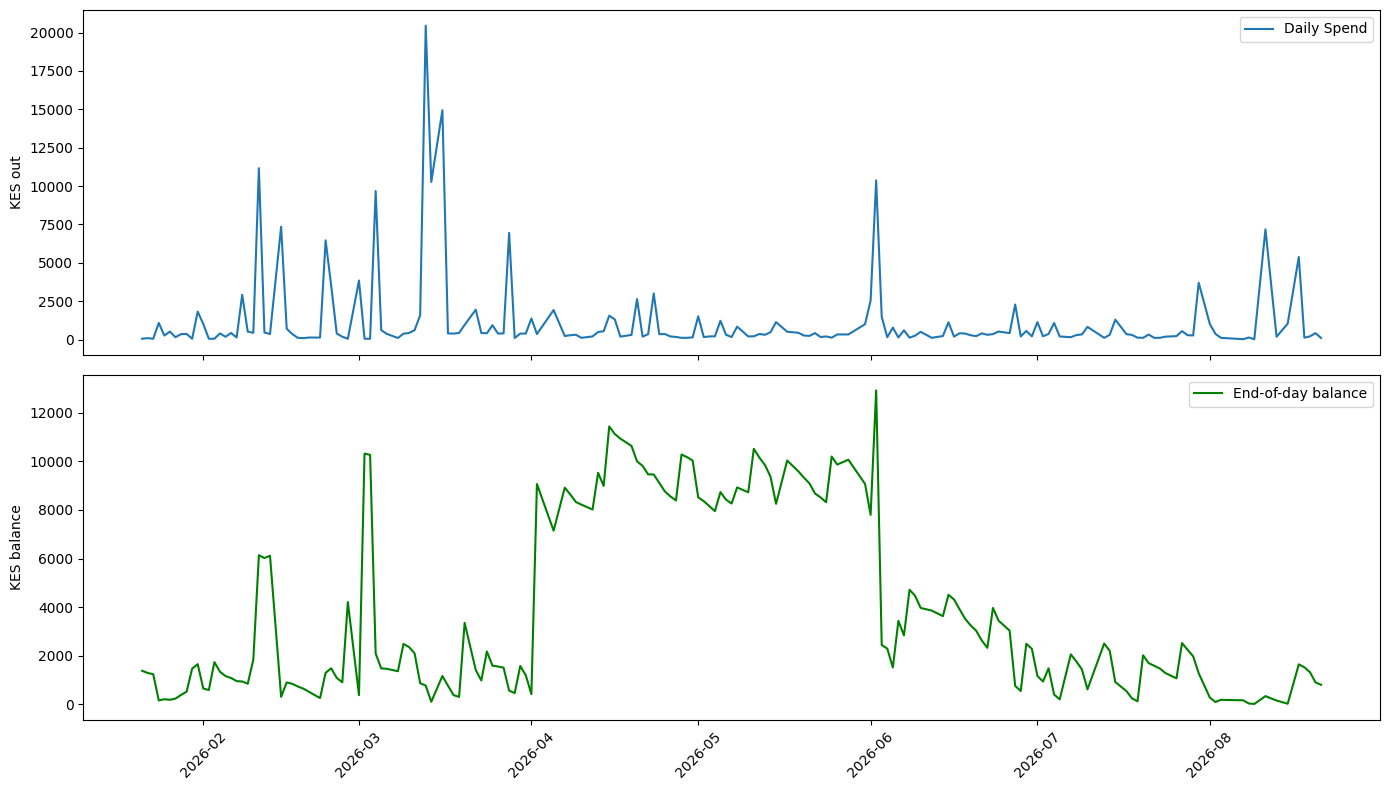


Days with spend > mean + 2 * std (6286 KES):
            day  total_out  total_in  n_transactions  end_balance
21   2026-02-11    11164.0   15400.0               8      6137.05
24   2026-02-15     7354.0    1550.0              18       312.05
32   2026-02-23     6459.0    7500.0               6      1302.05
40   2026-03-04     9675.0    1500.0               8      2092.05
48   2026-03-13    20449.0   20350.0               8       774.05
49   2026-03-14    10266.0    9600.0              14       108.05
50   2026-03-16    14939.0   16000.0              11      1169.05
61   2026-03-28     6944.0    6000.0              12       568.05
116  2026-06-02    10368.0    5500.0               8     12918.05
173  2026-08-11     7178.0    7500.0               9       341.05


In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,1,figsize=(14,8), sharex=True)
axes[0].plot(daily['day'], daily['total_out'], label='Daily Spend')
axes[0].set_ylabel('KES out')
axes[0].legend()
axes[1].plot(daily['day'], daily['end_balance'],color='green',  label='End-of-day balance')
axes[1].set_ylabel('KES balance')
axes[1].legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
threshold = daily['total_out'].mean()+ 2 * daily['total_out'].std()
print(f"\nDays with spend > mean + 2 * std ({threshold:.0f} KES):")
print(daily[daily['total_out'] > threshold])

In [ ]:
threshold_txn = aml['amount_out'].abs().mean()+ 2 * aml['amount_out'].abs().std()
big_txns = aml[aml['amount_out'].abs() >threshold_txn].sort_values('date')
print(big_txns[['date','category', 'amount_out' ,'balance']])

                   date          category  amount_out  balance
83  2026-02-11 20:19:44          pay_bill    -10500.0  6137.05
102 2026-02-15 15:09:00          pay_bill     -2800.0  1472.05
137 2026-02-23 08:18:44          pay_bill     -6000.0  1394.05
141 2026-02-24 17:39:19         buy_goods     -3325.0  1627.05
163 2026-03-04 12:24:52          pay_bill     -9000.0  2340.05
201 2026-03-13 15:45:54          pay_bill    -20000.0   824.05
208 2026-03-14 14:12:58  agent_withdrawal     -3500.0  3384.05
210 2026-03-14 14:26:19  agent_withdrawal     -3000.0   332.05
215 2026-03-14 15:37:03  agent_withdrawal     -3400.0   210.05
226 2026-03-16 13:03:40          pay_bill    -14000.0  1219.05
281 2026-03-28 16:22:24  agent_withdrawal     -6000.0   955.05
540 2026-06-02 22:35:58          pay_bill    -10000.0  2918.05
778 2026-07-30 12:12:55        send_money     -3500.0  1400.05
803 2026-08-11 16:27:28        send_money     -5250.0  2219.05
820 2026-08-17 13:36:43   mshwari_deposit     -5000.0  